In [18]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [19]:
df = pd.read_csv(r"C:\Users\Siddarood\Data Science 2\DS Morning 9th Feb 2026\DS Morning 9th Feb 2026\claimants.csv")

In [20]:
df.shape

(1340, 7)

In [21]:
df.head()

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038


* We are buliding a Model to Predict Weather the person is eligble to predict the Insurace claim.

In [22]:
df.duplicated().sum()

np.int64(0)

In [23]:
## Missing Values
df.isnull().sum()

CASENUM       0
ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

In [24]:
# Filling the missing columns with MODE The missing columns are discreate.
df.fillna({"CLMSEX":df.CLMSEX.mode()[0],"CLMINSUR":df.CLMINSUR.mode()[0],
           "SEATBELT":df.SEATBELT.mode()[0],"CLMAGE":df.CLMAGE.mode()[0]},inplace=True)

In [25]:
df.isnull().sum()

CASENUM     0
ATTORNEY    0
CLMSEX      0
CLMINSUR    0
SEATBELT    0
CLMAGE      0
LOSS        0
dtype: int64

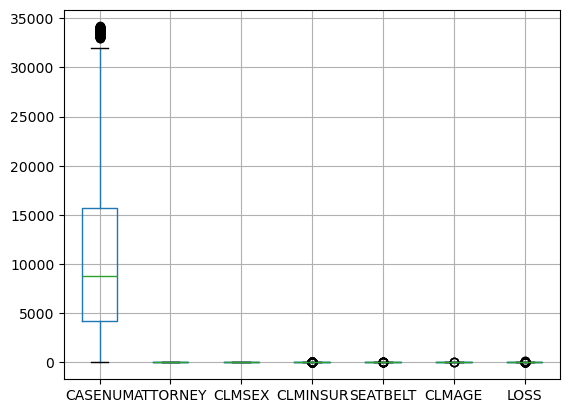

In [26]:
## Outliers
df.boxplot()
plt.show()

In [27]:
def Outlier_capping(df,column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3-Q1
    lower_extreme = Q1-1.5*IQR
    upper_extreme = Q3+1.5*IQR
    df[column] = df[column].apply(lambda x: lower_extreme if x<lower_extreme else upper_extreme if x>upper_extreme else x)
for col in df.select_dtypes(include=['int','float']).columns:
    Outlier_capping(df,col)

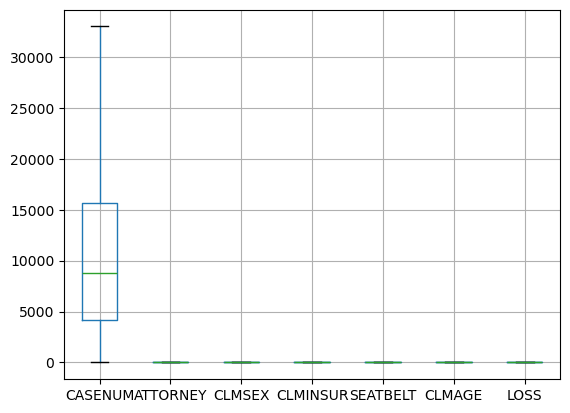

In [28]:
df.boxplot()
plt.show()

In [29]:
features = df.drop(columns=['CASENUM','ATTORNEY'])
target = df[['ATTORNEY']]

In [30]:
features.head()

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0.0,1.0,0.0,50.0,8.85375
1,1.0,1.0,0.0,18.0,0.89100
2,0.0,1.0,0.0,5.0,0.33000
3,0.0,1.0,0.0,31.0,0.03700
4,0.0,1.0,0.0,30.0,0.03800


In [31]:
x_train,x_test,y_train,y_test= train_test_split(features,target,train_size=0.8,random_state=100,stratify=target.ATTORNEY)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(1072, 5)
(268, 5)
(1072, 1)
(268, 1)


In [32]:
std_sca = StandardScaler()
x_train[['CLMAGE','LOSS']] = std_sca.fit_transform(x_train[['CLMAGE','LOSS']])
x_test[['CLMAGE','LOSS']] = std_sca.transform(x_test[['CLMAGE','LOSS']])

In [33]:
Model_Log_Reg = LogisticRegression()
Model_Log_Reg.fit(x_train,y_train)
y_pred= Model_Log_Reg.predict(x_test)
accuracy_score(y_test,y_pred)

0.7014925373134329

* Till Now we have Scaled the data handled the missing value and scaled the features data using Standard Scaler and trained with it the logistic regression which gave us the accuracy of 70%.

* Now for the next step our task is too Write and store the the data for model deployment.

* Here we are Saving the model in the pickel format means it will write and pack the data so we can use it and read it for the model deployment.

In [34]:
import pickle

In [35]:
file = 'Log_Model.pkl' # Namign the file
pickle.dump(Model_Log_Reg,open(file,'wb'))# WB here is writebyte

In [36]:
file1 = "Standard_scaler.pkl"
pickle.dump(std_sca, open(file1, 'wb'))

* We are saving the standard scaler to because entred data will not be in the scaled format for CLMAGE & Loss to scale in background and give result we are saving the scaler too.